# Exploración del corpus
Versión documentada el 26/10/2026: corpus simulado de 300 correos.
La selección y el diagnóstico usan 280/20; las versiones finales se ajustan con 10/100/200/300.
Los 25 de data/test no se usan en este notebook. La evaluación diagnóstica no demuestra generalización independiente de los modelos finales.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_config, project_path
from src.data_processing import load_data, split_data
config = load_config()
data = load_data(project_path(config["data_path"]))
train, test = split_data(data, config["test_size"], config["seed"], config["cv_folds"], holdout_manifest=project_path(config["holdout_manifest"]) if config.get("holdout_manifest") else None)


In [2]:
display(data[["clasificacion"]].head())
display(data.clasificacion.value_counts())
display(data.isna().sum())
display(data.texto.str.len().describe())

,clasificacion
0,accesos
1,accesos
2,accesos
3,accesos
4,accesos


clasificacion
aplicaciones       90
accesos            70
infraestructura    70
otros              70
Name: count, dtype: int64

clasificacion    0
cuerpo           0
titulo           0
texto            0
dtype: int64

count    300.000000
mean     409.263333
std      112.723686
min      279.000000
25%      320.000000
50%      350.000000
75%      532.000000
max      643.000000
Name: texto, dtype: float64

In [3]:
from src.train import export_eda
summary = export_eda(data)
summary

{'rows': 300,
 'class_counts': {'aplicaciones': 90,
  'accesos': 70,
  'infraestructura': 70,
  'otros': 70},
 'missing': {'clasificacion': 0, 'cuerpo': 0, 'titulo': 0, 'texto': 0},
 'length_characters': {'count': 300.0,
  'mean': 409.2633333333333,
  'std': 112.72368615464035,
  'min': 279.0,
  '25%': 320.0,
  '50%': 350.0,
  '75%': 532.0,
  'max': 643.0},
 'length_words': {'count': 300.0,
  'mean': 63.836666666666666,
  'std': 18.55057235427322,
  'min': 42.0,
  '25%': 49.0,
  '50%': 55.0,
  '75%': 85.0,
  'max': 100.0},
 'length_outliers_iqr': 0,
 'length_correlation': 0.9787861135670917}

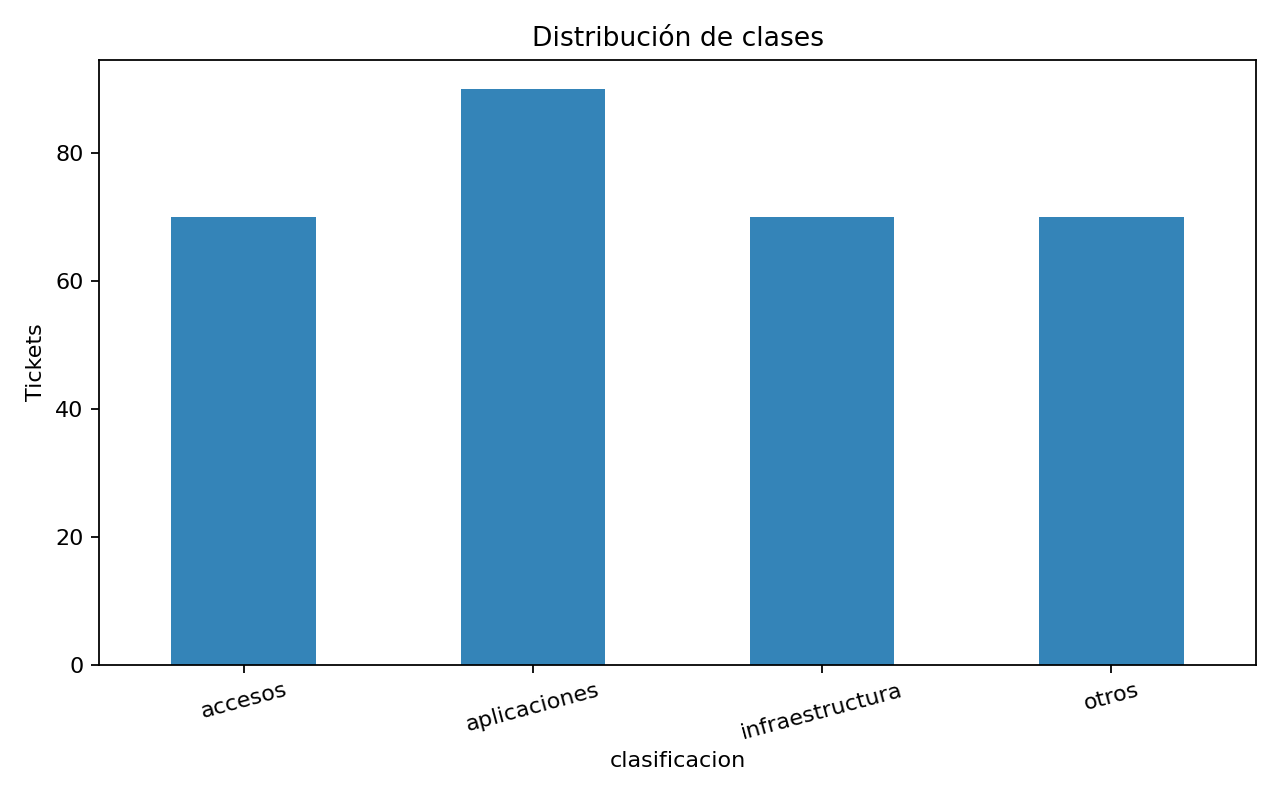

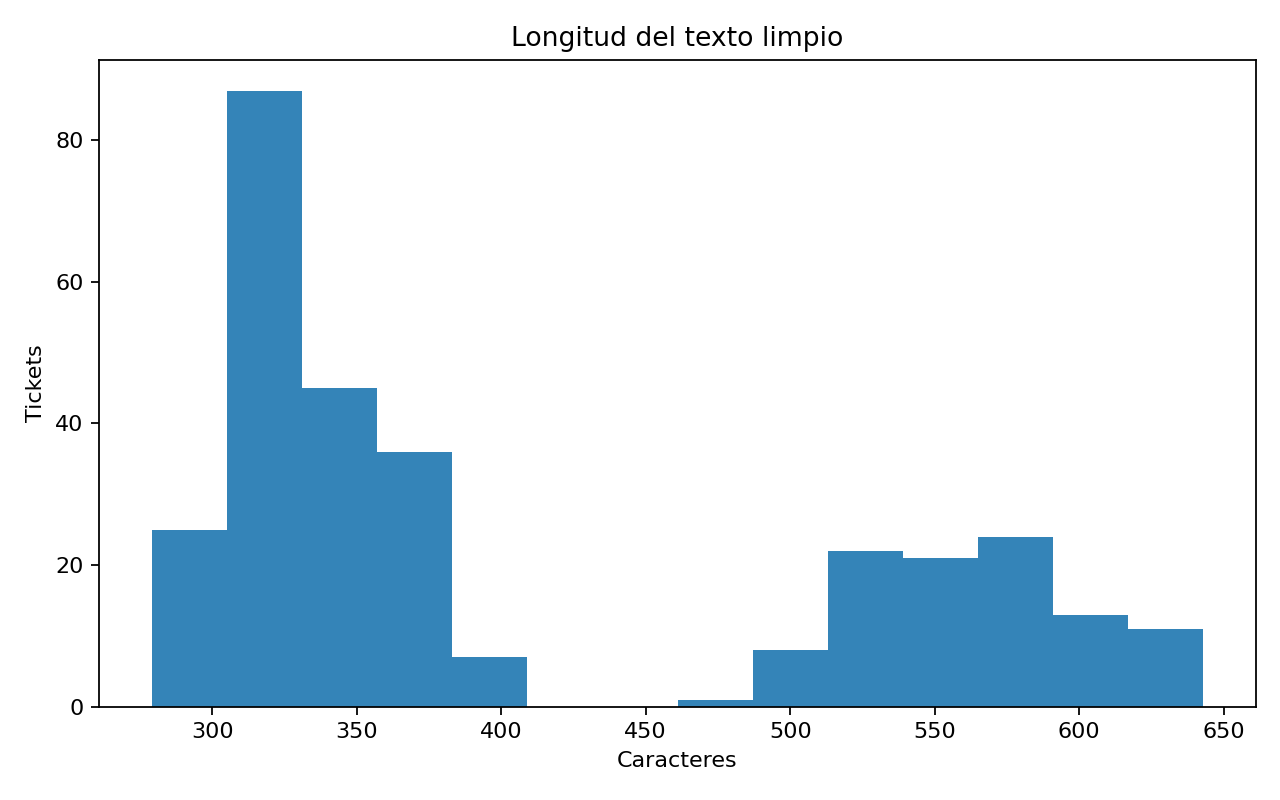

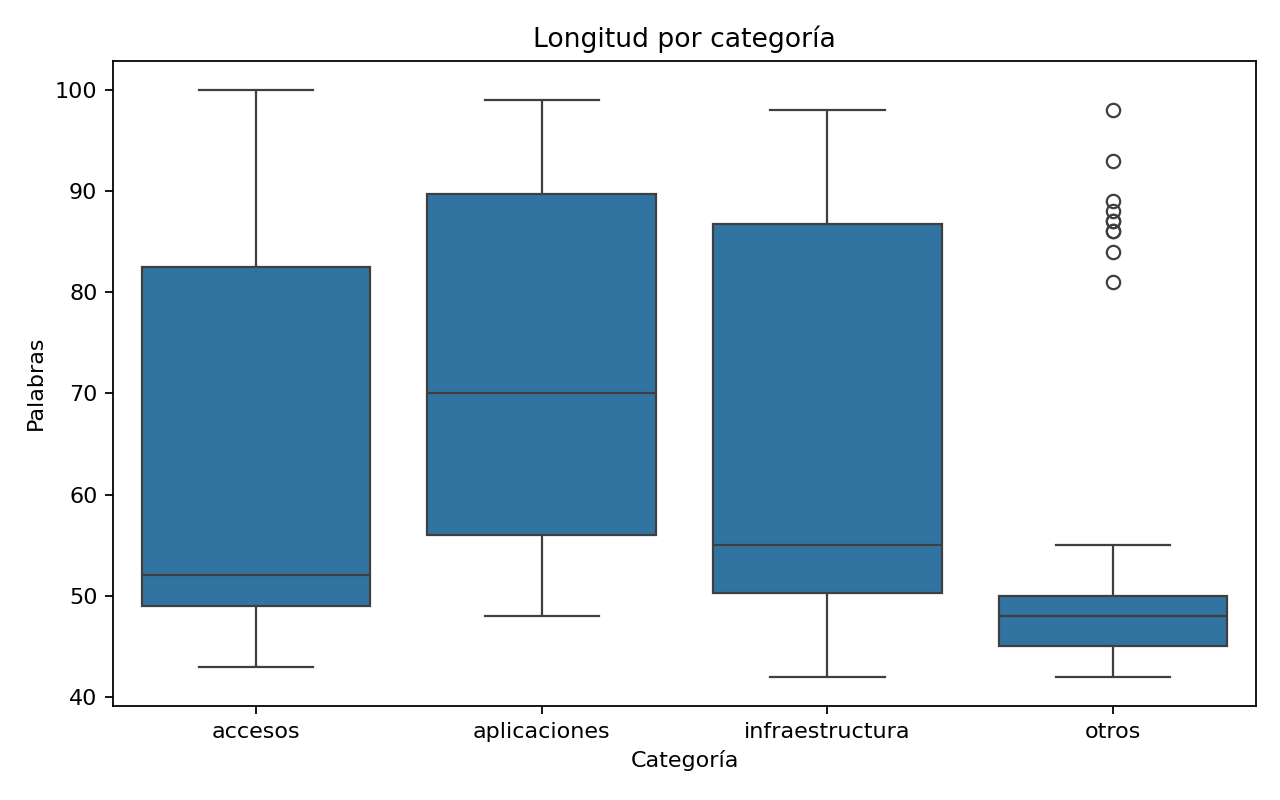

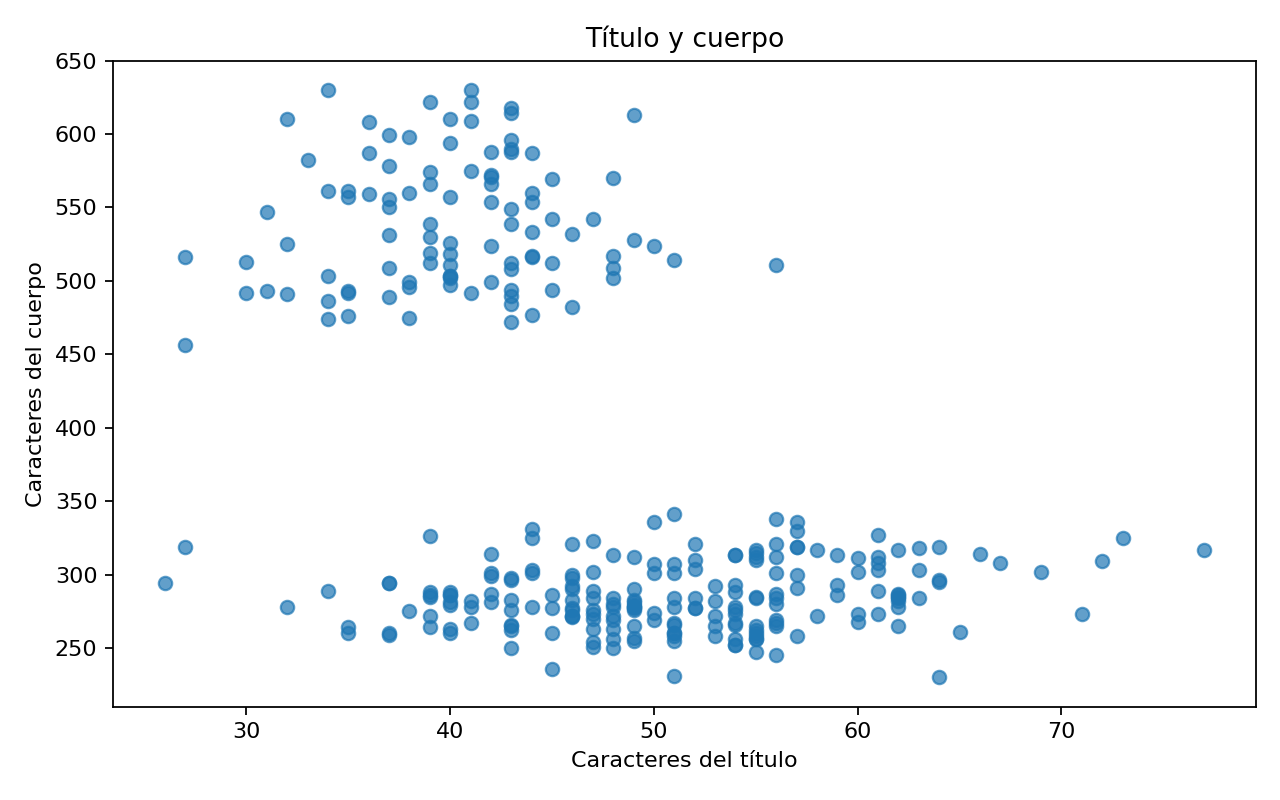

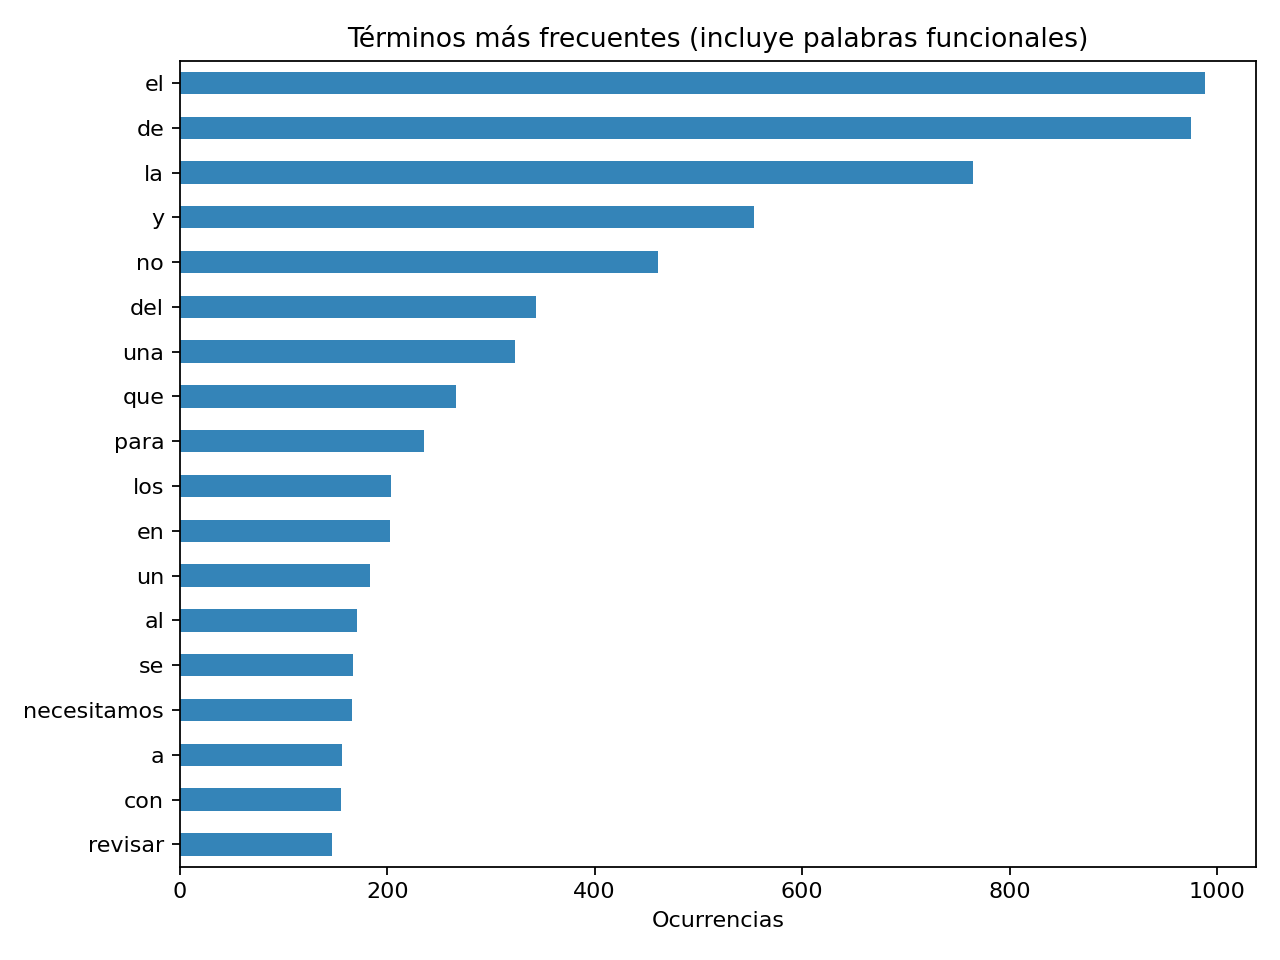

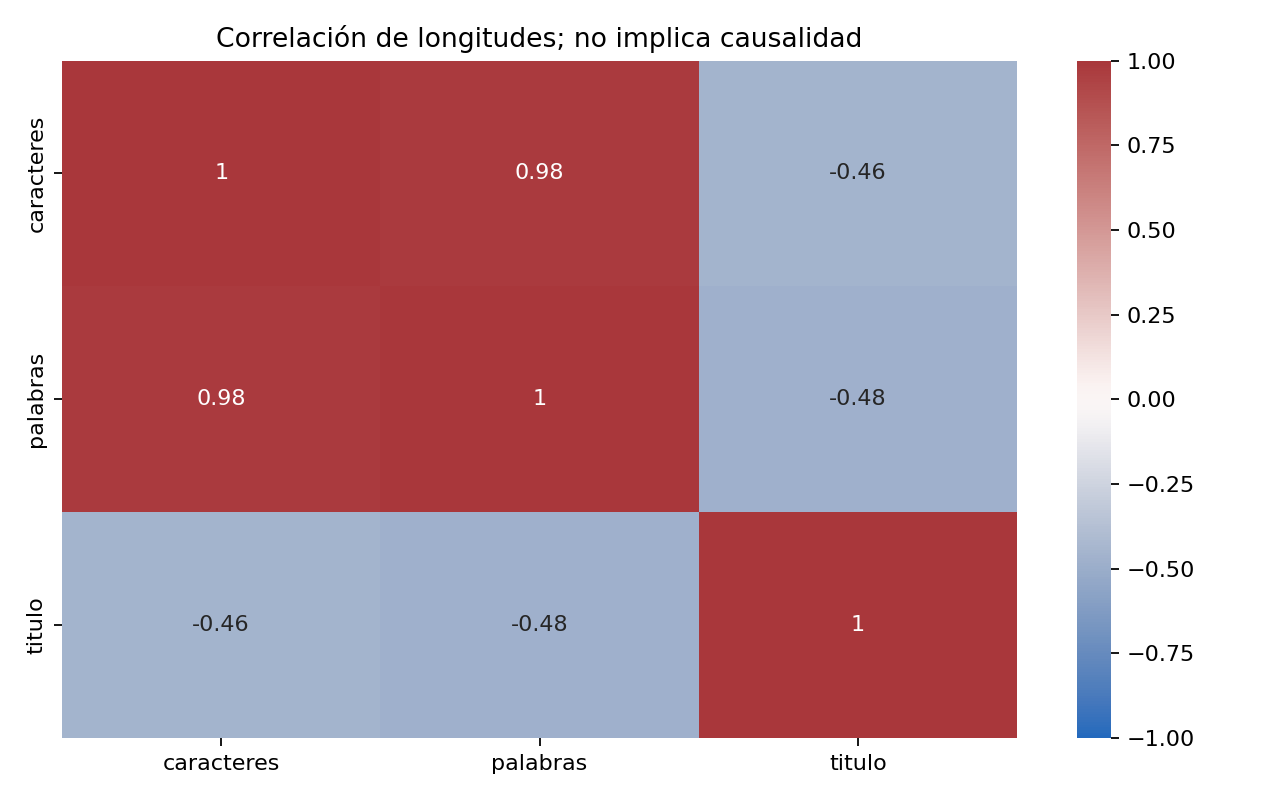

In [4]:
from IPython.display import Image, display
figures = ["01_class_distribution.png", "02_text_lengths.png",
           "03_words_by_class.png", "04_title_body.png",
           "05_common_terms.png", "06_length_correlations.png"]
for name in figures:
    display(Image(filename=str(ROOT / "documentacion/imagenes" / name)))